In [ ]:
import pandas as pd

df_air_quality = pd.read_csv("final_datasets/berlin_air_quality_2022_2026.csv")

df_air_quality.head()

,datetime,station,core,component,period,value,station_name,station_type
0,2021-12-31 23:00:00+00:00,mc010,no2,no2_24h,24h,19.0,Wedding,Urban background
1,2021-12-31 23:00:00+00:00,mc010,o3,o3_24h,24h,34.0,Wedding,Urban background
2,2021-12-31 23:00:00+00:00,mc010,pm10,pm10_24h,24h,18.0,Wedding,Urban background
3,2021-12-31 23:00:00+00:00,mc010,pm2,pm2_24h,24h,15.0,Wedding,Urban background
4,2021-12-31 23:00:00+00:00,mc027,no2,no2_24h,24h,5.0,Marienfelde,Outskirts


In [4]:
# Check dataset dimensions
print("Shape:", df_air_quality.shape)

# Check date range
print("\nDate range:")
print(df_air_quality["datetime"].min())
print(df_air_quality["datetime"].max())

# Check available pollutants
print("\nPollutants:")
print(df_air_quality["component"].value_counts())

# Check number of stations
print("\nNumber of stations:")
print(df_air_quality["station"].nunique())

# Check missing values
print("\nMissing values:")
print(df_air_quality.isna().sum())

# Preview dataset
display(df_air_quality.head())

Shape: (105112, 8)

Date range:
2021-12-31 23:00:00+00:00
2026-10-20 22:00:00+00:00

Pollutants:
component
no2_24h     25948
pm2_24h     20688
pm10_24h    20598
o3_24h      14036
no_24h       9735
nox_24h      9735
ebc_24h      2455
co_24h       1917
Name: count, dtype: int64

Number of stations:
15

Missing values:
datetime          0
station           0
core              0
component         0
period            0
value           731
station_name      0
station_type      0
dtype: int64


,datetime,station,core,component,period,value,station_name,station_type
0,2021-12-31 23:00:00+00:00,mc010,no2,no2_24h,24h,19.0,Wedding,Urban background
1,2021-12-31 23:00:00+00:00,mc010,o3,o3_24h,24h,34.0,Wedding,Urban background
2,2021-12-31 23:00:00+00:00,mc010,pm10,pm10_24h,24h,18.0,Wedding,Urban background
3,2021-12-31 23:00:00+00:00,mc010,pm2,pm2_24h,24h,15.0,Wedding,Urban background
4,2021-12-31 23:00:00+00:00,mc027,no2,no2_24h,24h,5.0,Marienfelde,Outskirts


In [5]:
# Copy the original dataset
air_quality = df_air_quality.copy()

# Convert timestamps from UTC to Berlin local time
air_quality["datetime"] = (
    pd.to_datetime(air_quality["datetime"], utc=True)
    .dt.tz_convert("Europe/Berlin")
)

# Extract local calendar date
air_quality["date"] = air_quality["datetime"].dt.date

# Keep the four pollutants available historically
main_pollutants = [
    "no2_24h",
    "o3_24h",
    "pm10_24h",
    "pm2_24h"
]

air_quality = air_quality[
    air_quality["component"].isin(main_pollutants)
].copy()

# Add year and month
air_quality["year"] = air_quality["datetime"].dt.year
air_quality["month"] = air_quality["datetime"].dt.month

# Check the result
print("Shape:", air_quality.shape)
print("\nLocal date range:")
print(air_quality["datetime"].min())
print(air_quality["datetime"].max())

print("\nRecords per pollutant:")
print(air_quality["component"].value_counts())

print("\nRecords per year:")
print(air_quality["year"].value_counts().sort_index())

Shape: (81270, 11)

Local date range:
2022-01-01 00:00:00+01:00
2026-10-21 00:00:00+02:00

Records per pollutant:
component
no2_24h     25948
pm2_24h     20688
pm10_24h    20598
o3_24h      14036
Name: count, dtype: int64

Records per year:
year
2022    16019
2023    17083
2024    17195
2025    17155
2026    13818
Name: count, dtype: int64


In [6]:
# Count records for each pollutant and year
pollutant_coverage = (
    air_quality
    .groupby(["year", "component"])
    .agg(
        records=("value", "count"),
        stations=("station", "nunique"),
        missing_values=("value", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(
    pollutant_coverage.pivot(
        index="year",
        columns="component",
        values="records"
    )
)

print("\nStation coverage by pollutant and year:")
display(
    pollutant_coverage.pivot(
        index="year",
        columns="component",
        values="stations"
    )
)

component,no2_24h,o3_24h,pm10_24h,pm2_24h
year,,,,
2022,5073,2896,3953,3953
2023,5455,2915,4278,4278
2024,5474,2920,4384,4384
2025,5471,2914,4371,4371
2026,4361,2323,3490,3490



Station coverage by pollutant and year:


component,no2_24h,o3_24h,pm10_24h,pm2_24h
year,,,,
2022,14,8,11,11
2023,15,8,12,12
2024,15,8,12,12
2025,15,8,12,12
2026,15,8,12,12


In [ ]:
# Filter air-quality data to summer months
summer_air_quality = air_quality[
    air_quality["month"].isin([6, 7, 8, 9])
].copy()

# Check coverage by year and pollutant
summer_coverage = (
    summer_air_quality
    .groupby(["year", "component"])
    .agg(
        records=("value", "count"),
        stations=("station", "nunique"),
        observed_dates=("date", "nunique"),
        missing_values=("value", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(summer_coverage)

,year,component,records,stations,observed_dates,missing_values
0,2022,no2_24h,1680,14,122,26
1,2022,o3_24h,960,8,122,16
2,2022,pm10_24h,1313,11,122,27
3,2022,pm2_24h,1313,11,122,27
4,2023,no2_24h,1821,15,122,9
5,2023,o3_24h,976,8,122,0
6,2023,pm10_24h,1391,12,122,11
7,2023,pm2_24h,1391,12,122,73
8,2024,no2_24h,1824,15,122,2
9,2024,o3_24h,975,8,122,1


In [9]:
# Calculate daily pollutant averages across reporting stations
air_daily = (
    summer_air_quality
    .groupby(["date", "component"])
    .agg(
        mean_concentration=("value", "mean"),
        stations_reporting=("value", "count")
    )
    .reset_index()
)

# Convert date to datetime for merging with weather data
air_daily["date"] = pd.to_datetime(air_daily["date"])

# Pivot pollutant concentrations into separate columns
air_daily_mean = air_daily.pivot(
    index="date",
    columns="component",
    values="mean_concentration"
)

# Pivot station counts into separate columns
air_daily_stations = air_daily.pivot(
    index="date",
    columns="component",
    values="stations_reporting"
)

# Rename station-count columns
air_daily_stations.columns = [
    f"{col}_stations" for col in air_daily_stations.columns
]

# Combine daily averages and station counts
air_daily_summary = pd.concat(
    [air_daily_mean, air_daily_stations],
    axis=1
).reset_index()

# Inspect the result
print("Shape:", air_daily_summary.shape)
display(air_daily_summary.head(10))

Shape: (610, 9)


,date,no2_24h,o3_24h,pm10_24h,pm2_24h,no2_24h_stations,o3_24h_stations,pm10_24h_stations,pm2_24h_stations
0,2022-06-01,17.571429,69.750,13.545455,8.545455,14,8,11,11
1,2022-06-02,17.142857,66.875,12.090909,7.818182,14,8,11,11
2,2022-06-03,19.214286,75.250,14.636364,8.636364,14,8,11,11
3,2022-06-04,8.714286,82.625,13.454545,8.272727,14,8,11,11
4,2022-06-05,8.000000,90.500,17.454545,12.000000,14,8,11,11
5,2022-06-06,11.500000,68.750,17.000000,11.818182,14,8,11,11
6,2022-06-07,19.571429,58.125,15.272727,7.909091,14,8,11,11
7,2022-06-08,21.500000,57.750,14.454545,7.272727,14,8,11,11
8,2022-06-09,19.642857,53.125,15.090909,8.818182,14,8,11,11
9,2022-06-10,15.285714,68.875,15.090909,7.727273,14,8,11,11


### number of stations used to measure pollutants:
- NO2 = 14
- O3 = 8
- PM10 and PM2.5= 11


In [ ]:
# Load weather dataset for weather/air quality visualizations

df_weather_data = pd.read_csv(
    "final_datasets/df_weather_combined_2022_2026.csv"
)

# Convert date to datetime
df_weather_data["date"] = pd.to_datetime(
    df_weather_data["date"]
)

# Check dataset
print("Shape:", df_weather_data.shape)
display(df_weather_data.head())

Shape: (14822, 13)


,station_id,date,tavg,tmin,tmax,prcp,wspd,tsun,cloud_cover,pres_dwd,station,source,pres_meteostat
0,NaN,2022-01-01,11.2,9.5,11.7,1.7,16.4,NaN,NaN,NaN,Alexanderplatz,Meteostat,1021.3
1,NaN,2022-01-02,9.5,8.1,10.9,2.0,17.7,NaN,NaN,NaN,Alexanderplatz,Meteostat,1013.0
2,NaN,2022-01-03,8.7,7.0,10.0,4.0,20.2,NaN,NaN,NaN,Alexanderplatz,Meteostat,1006.5
3,NaN,2022-01-04,6.8,5.4,7.7,3.0,12.1,NaN,NaN,NaN,Alexanderplatz,Meteostat,996.8
4,NaN,2022-01-05,3.7,3.0,4.9,2.3,18.8,NaN,NaN,NaN,Alexanderplatz,Meteostat,997.8


In [13]:
# Create one Tmax value per station and date
tmax_sources = df_weather_data.pivot_table(
    index=["station", "date"],
    columns="source",
    values="tmax",
    aggfunc="first"
)

# Prefer DWD and use Meteostat as fallback
weather_tmax = pd.DataFrame(index=tmax_sources.index)

weather_tmax["tmax"] = (
    tmax_sources["DWD"].combine_first(tmax_sources["Meteostat"])
)

# Record which source supplied the value
weather_tmax["tmax_source"] = "Missing"

weather_tmax.loc[
    tmax_sources["DWD"].notna(),
    "tmax_source"
] = "DWD"

weather_tmax.loc[
    tmax_sources["DWD"].isna() & tmax_sources["Meteostat"].notna(),
    "tmax_source"
] = "Meteostat"

weather_tmax = weather_tmax.reset_index()

# Check the result
print("Shape:", weather_tmax.shape)
print("\nSource distribution:")
display(weather_tmax["tmax_source"].value_counts())

display(weather_tmax.head())

Shape: (12252, 4)

Source distribution:


tmax_source
DWD          8183
Meteostat    4069
Name: count, dtype: int64

,station,date,tmax,tmax_source
0,Alexanderplatz,2022-01-01,11.7,Meteostat
1,Alexanderplatz,2022-01-02,10.9,Meteostat
2,Alexanderplatz,2022-01-03,10.0,Meteostat
3,Alexanderplatz,2022-01-04,7.7,Meteostat
4,Alexanderplatz,2022-01-05,4.9,Meteostat


In [14]:
# Keep summer months (June to September)
summer_weather = weather_tmax[
    weather_tmax["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Calculate daily temperature averages across available stations
berlin_daily_weather = (
    summer_weather
    .groupby("date")
    .agg(
        mean_station_tmax=("tmax", "mean"),
        stations_available=("station", "nunique"),
        min_station_tmax=("tmax", "min"),
        max_station_tmax=("tmax", "max")
    )
    .reset_index()
)

# Add year
berlin_daily_weather["year"] = berlin_daily_weather["date"].dt.year

# Check results
print("Shape:", berlin_daily_weather.shape)
print("\nStation availability:")
print(berlin_daily_weather["stations_available"].value_counts().sort_index())

display(berlin_daily_weather.head())

Shape: (610, 6)

Station availability:
stations_available
6     21
7    589
Name: count, dtype: int64


,date,mean_station_tmax,stations_available,min_station_tmax,max_station_tmax,year
0,2022-06-01,19.614286,7,18.1,20.5,2022
1,2022-06-02,19.633333,6,17.9,20.4,2022
2,2022-06-03,25.250000,6,23.0,26.1,2022
3,2022-06-04,24.333333,6,23.3,25.0,2022
4,2022-06-05,28.033333,6,26.5,28.7,2022


In [15]:
# Merge daily air quality and weather data
air_weather = air_daily_summary.merge(
    berlin_daily_weather[
        ["date", "mean_station_tmax", "stations_available"]
    ],
    on="date",
    how="inner",
    validate="one_to_one"
)

# Classify days based on mean station Tmax
air_weather["day_type"] = (
    air_weather["mean_station_tmax"]
    .ge(30)
    .map({True: "Hot", False: "Non-hot"})
)

# Add year
air_weather["year"] = air_weather["date"].dt.year

# Check merged dataset
print("Shape:", air_weather.shape)
print("\nDay type distribution:")
print(air_weather["day_type"].value_counts())

display(air_weather.head())

Shape: (610, 13)

Day type distribution:
day_type
Non-hot    546
Hot         64
Name: count, dtype: int64


,date,no2_24h,o3_24h,pm10_24h,pm2_24h,no2_24h_stations,o3_24h_stations,pm10_24h_stations,pm2_24h_stations,mean_station_tmax,stations_available,day_type,year
0,2022-06-01,17.571429,69.750,13.545455,8.545455,14,8,11,11,19.614286,7,Non-hot,2022
1,2022-06-02,17.142857,66.875,12.090909,7.818182,14,8,11,11,19.633333,6,Non-hot,2022
2,2022-06-03,19.214286,75.250,14.636364,8.636364,14,8,11,11,25.250000,6,Non-hot,2022
3,2022-06-04,8.714286,82.625,13.454545,8.272727,14,8,11,11,24.333333,6,Non-hot,2022
4,2022-06-05,8.000000,90.500,17.454545,12.000000,14,8,11,11,28.033333,6,Non-hot,2022


In [16]:
# Define the four main pollutants
pollutants = [
    "no2_24h",
    "o3_24h",
    "pm10_24h",
    "pm2_24h"
]

# Compare pollutant concentrations by day type
air_quality_comparison = (
    air_weather
    .groupby("day_type")[pollutants]
    .agg(["mean", "median", "count"])
    .round(2)
)

display(air_quality_comparison)

no2_24h              o3_24h              pm10_24h               \
            mean median count   mean median count     mean median count   
day_type                                                                  
Hot        15.58  14.41    64  84.13  83.51    64    22.61  21.44    64   
Non-hot    13.17  12.67   546  58.40  57.75   546    15.40  14.33   546   

         pm2_24h               
            mean median count  
day_type                       
Hot        11.17  10.46    64  
Non-hot     8.60   8.00   546

Ozone (O₃): substantially higher on hot days, with a 44.1% increase.

PM10: shows the largest relative increase, at 46.8%.

PM2.5: also increases, by 29.9%.

NO₂: increases more moderately, by 18.3%.

In [17]:
# Compare pollutant concentrations by year and day type
yearly_air_comparison = (
    air_weather
    .groupby(["year", "day_type"])[pollutants]
    .mean()
    .round(2)
)

display(yearly_air_comparison)

no2_24h  o3_24h  pm10_24h  pm2_24h
year day_type                                    
2022 Hot         19.51   87.88     24.46    11.65
     Non-hot     14.48   57.86     15.37     8.48
2023 Hot         18.75   75.90     21.28    12.29
     Non-hot     14.91   59.75     16.47     9.28
2024 Hot         13.24   84.79     26.34    12.17
     Non-hot     12.73   60.96     17.08     9.67
2025 Hot         14.13   88.22     21.64    10.28
     Non-hot     12.29   55.00     14.15     8.10
2026 Hot         12.76   82.30     19.23     9.84
     Non-hot     11.39   58.50     13.88     7.39

O₃: consistently elevated, with the largest difference in 2025 (88.22 vs 55.00).

PM10: consistently higher, with the largest absolute difference in 2024 (26.34 vs 17.08).

PM2.5: higher every year, although the difference is relatively modest.

NO₂: also higher every year, but the difference narrows in 2024–2026.

In [ ]:
# Count hot and non-hot days by year, where hot >= 30 C
yearly_day_counts = (
    air_weather
    .groupby(["year", "day_type"])
    .size()
    .unstack(fill_value=0)
)

display(yearly_day_counts)

day_type,Hot,Non-hot
year,,
2022,16,106
2023,9,113
2024,13,109
2025,9,113
2026,17,105


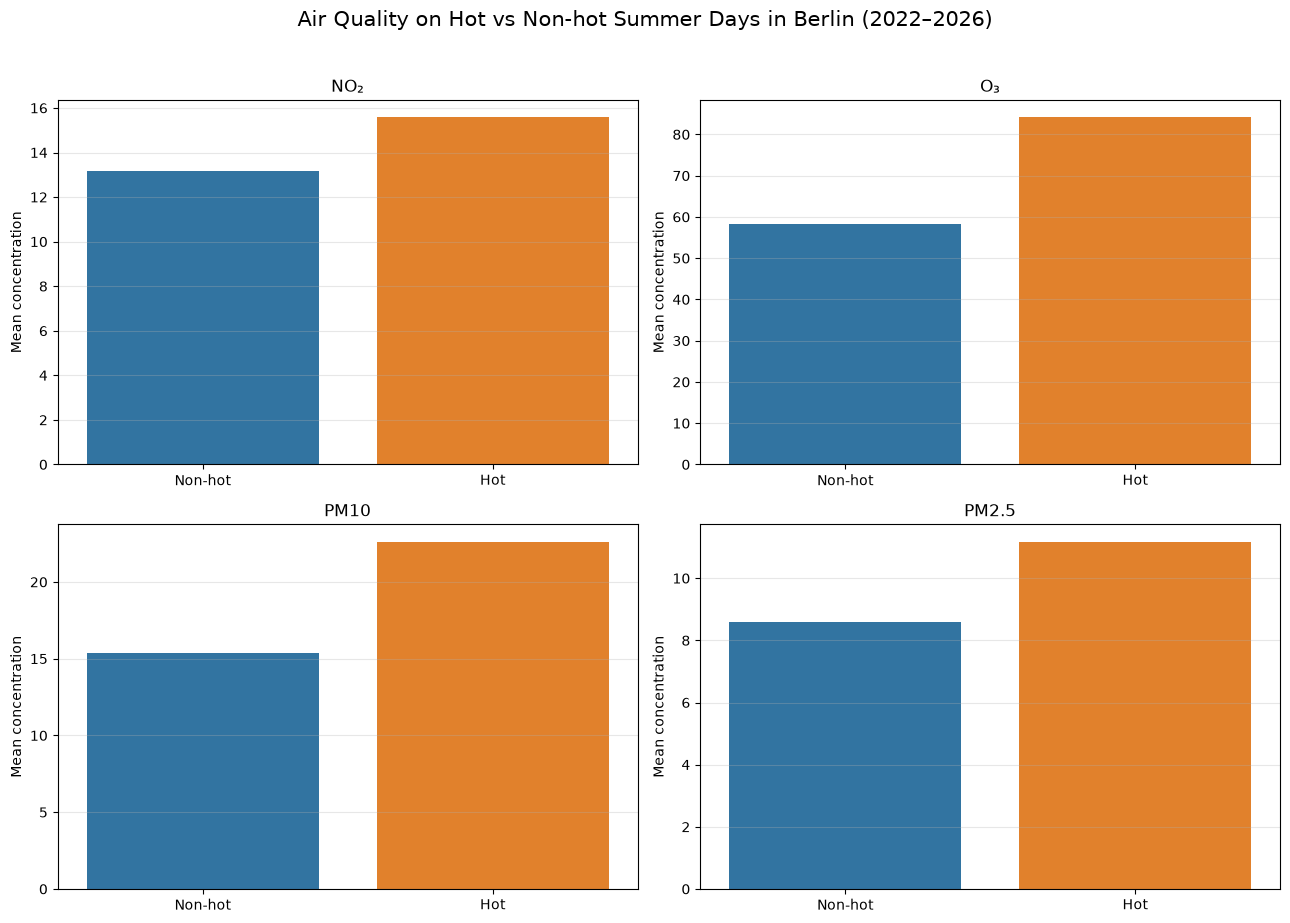

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate mean concentrations by day type
plot_data = (
    air_weather
    .groupby("day_type")[pollutants]
    .mean()
    .reset_index()
)

# Convert to long format for plotting
plot_data_long = plot_data.melt(
    id_vars="day_type",
    value_vars=pollutants,
    var_name="pollutant",
    value_name="mean_concentration"
)

# Create pollutant labels
pollutant_labels = {
    "no2_24h": "NO₂",
    "o3_24h": "O₃",
    "pm10_24h": "PM10",
    "pm2_24h": "PM2.5"
}

plot_data_long["pollutant"] = (
    plot_data_long["pollutant"].map(pollutant_labels)
)

# Plot
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, pollutant in zip(
    axes.flat,
    ["NO₂", "O₃", "PM10", "PM2.5"]
):
    sns.barplot(
        data=plot_data_long[
            plot_data_long["pollutant"] == pollutant
        ],
        x="day_type",
        y="mean_concentration",
        hue="day_type",
        order=["Non-hot", "Hot"],
        hue_order=["Non-hot", "Hot"],
        legend=False,
        ax=ax
    )

    ax.set_title(pollutant)
    ax.set_xlabel("")
    ax.set_ylabel("Mean concentration")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Air Quality on Hot vs Non-hot Summer Days in Berlin (2022–2026)",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

- Higher concentrations across all four pollutants: Mean NO₂, O₃, PM₁₀ and PM₂.₅ concentrations were higher on hot days (daily mean Tmax ≥30°C) than on non-hot summer days.
- Strongest relative increase in ozone (O₃): Mean concentration increased from 58.40 to 84.13 µg/m³ (+44.1%). This is consistent with the established relationship between strong sunlight, high temperatures and photochemical ozone formation.
- Particulate matter also increased: PM₁₀ rose from 15.40 to 22.61 µg/m³ (+46.8%), while PM₂.₅ increased from 8.60 to 11.17 µg/m³ (+29.9%).
- Moderate increase in nitrogen dioxide (NO₂): Mean concentration rose from 13.17 to 15.58 µg/m³ (+18.3%).

Percentages are calculated relative to the non-hot-day mean. The dataset contains 64 hot days and 546 non-hot days.

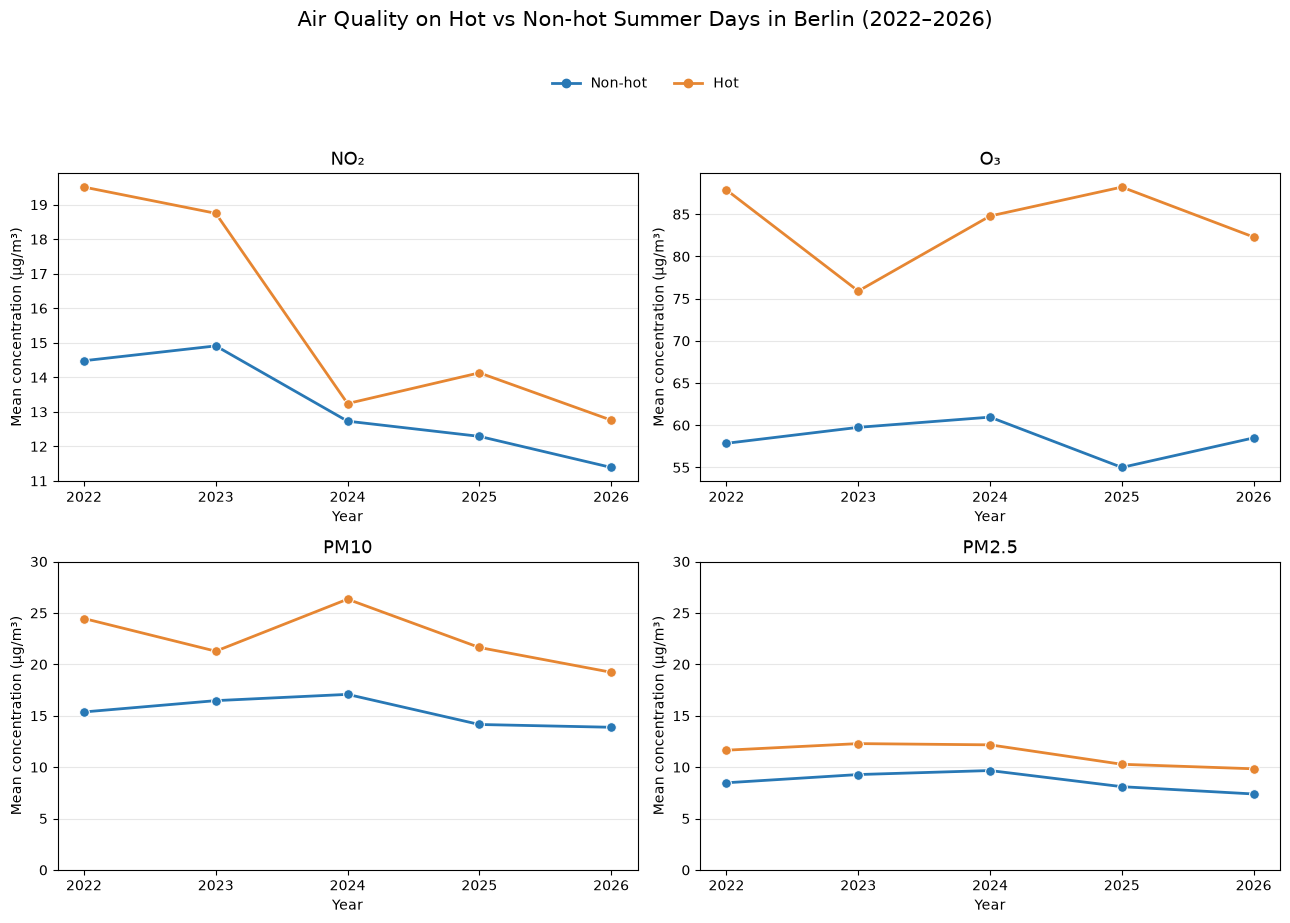

In [21]:
# Define consistent colours
day_colors = {
    "Non-hot": "#2878B5",
    "Hot": "#E68632"
}

# Create 2x2 chart
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

pollutant_order = ["NO₂", "O₃", "PM10", "PM2.5"]

for ax, pollutant in zip(axes.flat, pollutant_order):

    pollutant_data = yearly_plot_data[
        yearly_plot_data["pollutant"] == pollutant
    ]

    sns.lineplot(
        data=pollutant_data,
        x="year",
        y="mean_concentration",
        hue="day_type",
        hue_order=["Non-hot", "Hot"],
        palette=day_colors,
        marker="o",
        markersize=7,
        linewidth=2,
        errorbar=None,
        legend=False,
        ax=ax
    )

    ax.set_title(pollutant, fontsize=13)
    ax.set_xlabel("Year")
    ax.set_ylabel("Mean concentration (µg/m³)")
    ax.set_xticks([2022, 2023, 2024, 2025, 2026])
    ax.grid(axis="y", alpha=0.3)

# Synchronise particulate matter scales
axes[1, 0].set_ylim(0, 30)
axes[1, 1].set_ylim(0, 30)

# Create one shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()

from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        color=day_colors[label],
        marker="o",
        linewidth=2,
        label=label
    )
    for label in ["Non-hot", "Hot"]
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.96),
    frameon=False
)

fig.suptitle(
    "Air Quality on Hot vs Non-hot Summer Days in Berlin (2022–2026)",
    fontsize=15,
    y=1.02
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

1. Consistently higher concentrations on hot days

Across all five summers, all four pollutants (NO₂, O₃, PM₁₀ and PM₂.₅) had higher mean concentrations on hot days (daily mean Tmax ≥30°C) than on non-hot days.

2. Ozone showed the strongest contrast in 2025

O₃ reached 88.22 µg/m³ on hot days in 2025, compared with 55.00 µg/m³ on non-hot days — the largest difference between the two day types across the five years.

3. Particulate matter showed different yearly patterns
- PM₁₀ peaked on hot days in 2024 at 26.34 µg/m³.
- PM₂.₅ also peaked in 2024 at 12.17 µg/m³.
- PM₂.₅ concentrations remained below half of PM₁₀ concentrations in every yearly hot/non-hot comparison.

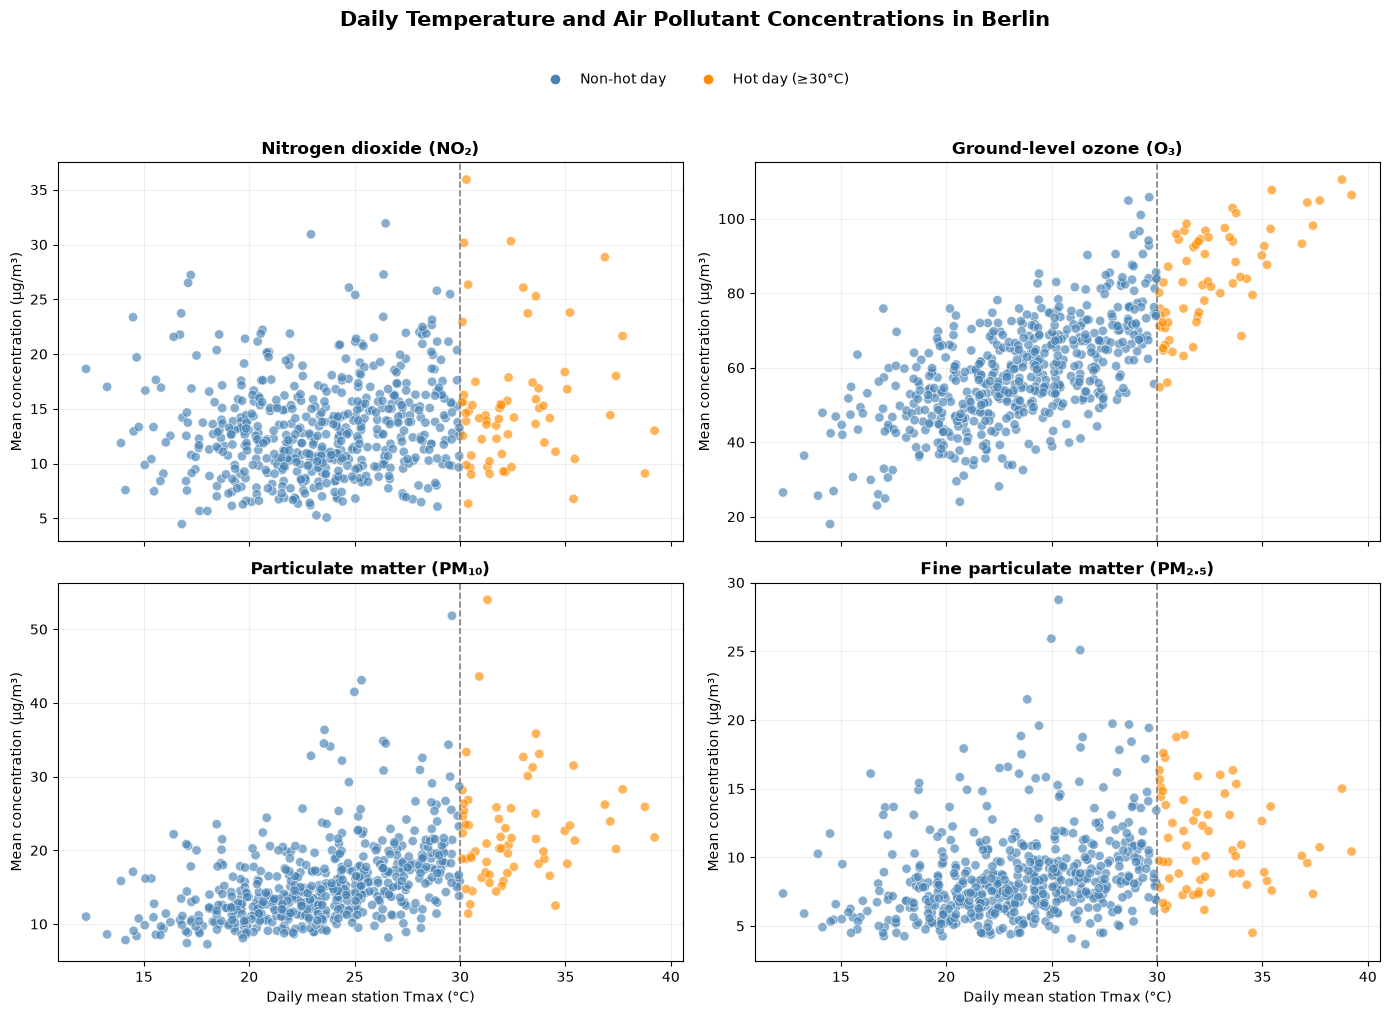

In [22]:
# Create a 2x2 scatter plot comparing temperature and air quality

pollutants = {
    "no2_24h": "Nitrogen dioxide (NO₂)",
    "o3_24h": "Ground-level ozone (O₃)",
    "pm10_24h": "Particulate matter (PM₁₀)",
    "pm2_24h": "Fine particulate matter (PM₂.₅)"
}

# Create the figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

axes = axes.flatten()

# Define colours for hot and non-hot days
palette = {
    "Non-hot": "steelblue",
    "Hot": "darkorange"
}

# Create one scatter plot per pollutant
for ax, (pollutant, title) in zip(axes, pollutants.items()):

    sns.scatterplot(
        data=air_weather,
        x="mean_station_tmax",
        y=pollutant,
        hue="day_type",
        hue_order=["Non-hot", "Hot"],
        palette=palette,
        alpha=0.65,
        s=45,
        ax=ax,
        legend=False
    )

    # Mark the 30°C hot-day threshold
    ax.axvline(
        x=30,
        color="grey",
        linestyle="--",
        linewidth=1.2
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Daily mean station Tmax (°C)")
    ax.set_ylabel("Mean concentration (µg/m³)")
    ax.grid(alpha=0.2)

# Add a shared legend
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           label="Non-hot day", markerfacecolor="steelblue",
           markersize=8),
    Line2D([0], [0], marker="o", color="w",
           label="Hot day (≥30°C)", markerfacecolor="darkorange",
           markersize=8)
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    "Daily Temperature and Air Pollutant Concentrations in Berlin",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [23]:
# Check pollutant ranges and temperature correlations

pollutants = ["no2_24h", "o3_24h", "pm10_24h", "pm2_24h"]

correlation_results = []

for pollutant in pollutants:

    valid_data = air_weather[
        ["mean_station_tmax", pollutant]
    ].dropna()

    correlation_results.append({
        "pollutant": pollutant,
        "observations": len(valid_data),
        "minimum": valid_data[pollutant].min(),
        "maximum": valid_data[pollutant].max(),
        "pearson_r": valid_data["mean_station_tmax"].corr(
            valid_data[pollutant],
            method="pearson"
        ),
        "spearman_r": valid_data["mean_station_tmax"].corr(
            valid_data[pollutant],
            method="spearman"
        )
    })

correlation_summary = pd.DataFrame(correlation_results).round(2)

correlation_summary

,pollutant,observations,minimum,maximum,pearson_r,spearman_r
0,no2_24h,610,4.47,35.93,0.19,0.19
1,o3_24h,610,18.00,110.50,0.73,0.69
2,pm10_24h,610,7.25,54.00,0.51,0.57
3,pm2_24h,610,3.67,28.75,0.33,0.39


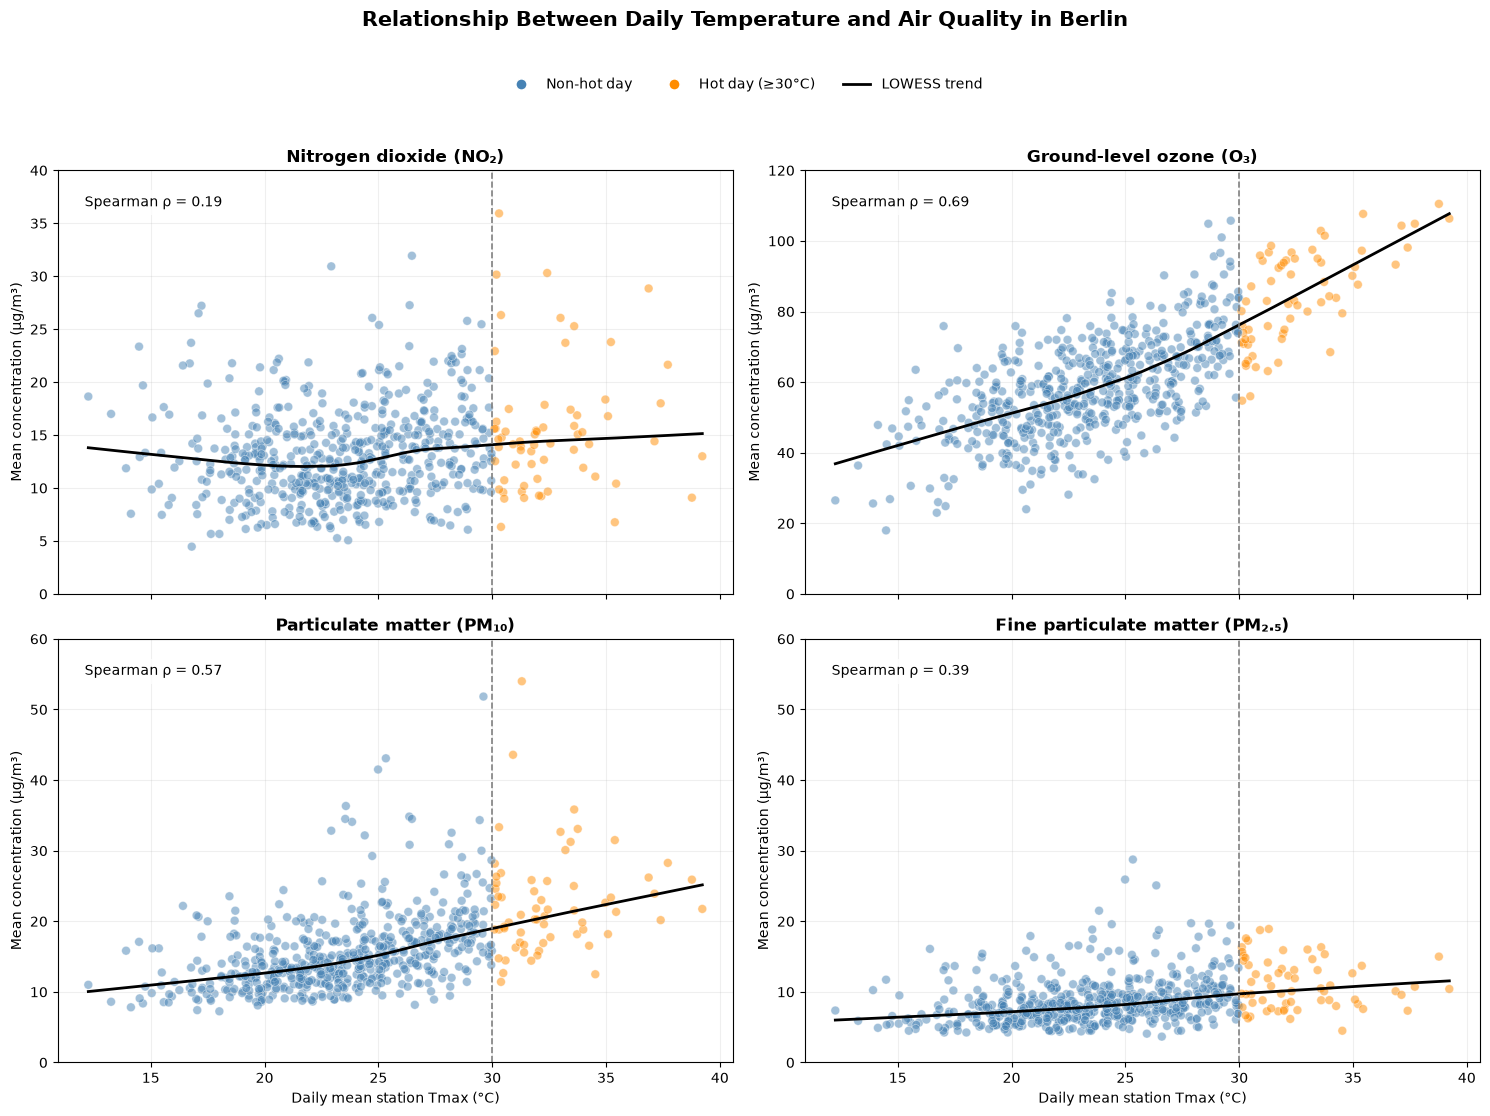

In [ ]:
# Improved temperature and air-quality relationship chart

pollutants = {
    "no2_24h": "Nitrogen dioxide (NO₂)",
    "o3_24h": "Ground-level ozone (O₃)",
    "pm10_24h": "Particulate matter (PM₁₀)",
    "pm2_24h": "Fine particulate matter (PM₂.₅)"
}

y_limits = {
    "no2_24h": (0, 40),
    "o3_24h": (0, 120),
    "pm10_24h": (0, 60),
    "pm2_24h": (0, 60)
}

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True)
axes = axes.flatten()

palette = {
    "Non-hot": "steelblue",
    "Hot": "darkorange"
}

for ax, (pollutant, title) in zip(axes, pollutants.items()):

    # Scatter plot
    sns.scatterplot(
        data=air_weather,
        x="mean_station_tmax",
        y=pollutant,
        hue="day_type",
        hue_order=["Non-hot", "Hot"],
        palette=palette,
        alpha=0.5,
        s=40,
        ax=ax,
        legend=False
    )

    # Add LOWESS trend curve (local regression curve)
    sns.regplot(
        data=air_weather,
        x="mean_station_tmax",
        y=pollutant,
        lowess=True,
        scatter=False,
        color="black",
        line_kws={"linewidth": 2},
        ax=ax
    )

    # Add 30°C threshold
    ax.axvline(
        x=30,
        color="grey",
        linestyle="--",
        linewidth=1.2
    )

    # Add Spearman correlation
    rho = air_weather["mean_station_tmax"].corr(
        air_weather[pollutant],
        method="spearman"
    )

    ax.text(
        0.04, 0.94,
        f"Spearman ρ = {rho:.2f}",
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="top",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none"
        )
    )

    # Set labels and limits
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Daily mean station Tmax (°C)")
    ax.set_ylabel("Mean concentration (µg/m³)")
    ax.set_ylim(y_limits[pollutant])
    ax.grid(alpha=0.2)

# Shared legend
from matplotlib.lines import Line2D

legend_elements = [
    Line2D(
        [0], [0], marker="o", color="w",
        label="Non-hot day",
        markerfacecolor="steelblue", markersize=8
    ),
    Line2D(
        [0], [0], marker="o", color="w",
        label="Hot day (≥30°C)",
        markerfacecolor="darkorange", markersize=8
    ),
    Line2D(
        [0], [0], color="black",
        label="LOWESS trend", linewidth=2
    )
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    "Relationship Between Daily Temperature and Air Quality in Berlin",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

- Ozone (O₃) showed the strongest positive association with temperature (Spearman ρ = 0.69). Higher temperatures generally coincided with higher ozone concentrations, consistent with the temperature- and sunlight-dependent processes involved in ground-level ozone formation.
- PM₁₀ showed a moderate positive association (ρ = 0.57), suggesting that particulate concentrations also tended to increase on warmer summer days.
- PM₂.₅ showed a weaker positive association (ρ = 0.39), indicating a less pronounced relationship with temperature than PM₁₀.
- NO₂ showed only a weak positive association (ρ = 0.19), suggesting that its daily concentrations varied less consistently with temperature.

610 daily observations per pollutant.

Five summer periods (2022–2026).

Spearman correlation calculated across all observations.

Daily station averages, not individual station measurements.